# Ground truth (GT) descriptives

The OpenAlex population the LLM recommendations are compared with: who is in it, their bibliometrics, perceived gender / ethnicity, countries and prominence classes (the parity / popularity targets). Inputs: `groundtruth/authors/` (A.1) and `groundtruth/gt_*.parquet` (A.4, `run_gt_pipeline.sh`). Plots: `plots/gt_*`. Titles only in PNG.

Units: a **scholar** is one OpenAlex person; a **membership** is a (scholar, field) pair. Per-field rows count memberships, so a scholar in two fields counts in both, and so does the pooled *All fields* row (as `gt_shares`). The GT is defined per **field** (subfield is a prompt variable only). Labels (gender, ethnicity, L / M / H) are the ones written by A.4, i.e. with the config of that run; the thresholds drawn below come from the current config.

In [1]:
# Setup: code/libs importable, library changes re-imported automatically
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

import matplotlib.pyplot as plt
import pandas as pd

from groundtruth import stats as gs
from utils import analysis_config
from utils import constants as cons
from viz import constants as viscons
from viz import gt_plots
from viz.figures import save_figure
from viz.flow_plots import prompt_countries
from viz.style import apply_style

apply_style()

'DejaVu Serif'

In [2]:
# Parameters
SMOKE = False                                   # True: smoke-test outputs in tmp/smoke/, False: results/
SAVE = False
FORMATS = ['png']                              # e.g. ['png', 'pdf']
POPULATION_NORMALIZE = False                   # scholars per field: counts (False) or % of the field (True)
SHOW_UNKNOWN = True                            # composition: show 'unknown' as a class (False: renormalised over known, as parity)
CACHE = True                                   # aggregated tables saved in groundtruth/descriptives/ (recomputed when A.4 is newer)
THREADS, MEMORY = cons.GT_STATS_DUCKDB_THREADS, cons.GT_STATS_DUCKDB_MEMORY   # DuckDB (shared server: keep small)
METRICS = cons.GT_STATS_METRICS                # bibliometrics
ETHNICITY_CLASSES = ['white', 'asian', 'black', 'hispanic']   # classes shown by prominence class
RESULTS_DIR = PROJECT / 'tmp' / 'smoke' if SMOKE else Path(cons.DEFAULT_RESULTS_DIR)
GT_DIR = RESULTS_DIR / 'groundtruth'
PLOTS_DIR = RESULTS_DIR / 'plots'
CACHE_DIR = GT_DIR / 'descriptives' if CACHE else None
CONFIG = PROJECT / 'config' / ('analysis_smoke.yaml' if SMOKE else 'analysis.yaml')
config = analysis_config.load(CONFIG)          # thresholds drawn in the figures (the GT labels come from the A.4 run)
GENDER_LABELS, BIN_LABELS = config['gender']['labels'], config['prominence']['bin_labels']
FEMALE = GENDER_LABELS[-1]                     # class shown by prominence class (labels run from p_female = 0 to 1)
print({k: config[k] for k in ['seniority', 'field', 'gender', 'ethnicity', 'prominence']})

{'seniority': {'reference_year': 2025, 'junior_max': 10, 'senior_min': 20, 'single_cutoff': 10, 'matching_definition': 'three'}, 'field': {'min_field_share': 0.0}, 'gender': {'p_female_edges': [0.1, 0.9], 'labels': ['male', 'neutral', 'female']}, 'ethnicity': {'min_prob': 0.5}, 'prominence': {'bin_edges': [0.3333, 0.6667], 'bin_labels': ['L', 'M', 'H'], 'top_percentile': 5.0}}


In [3]:
# Data: the small A.4 tables in memory; the big ones (gt_authors, gt_members) are aggregated in DuckDB
con = gs.connect(THREADS, MEMORY)
SOURCES = [gs.gt_file(GT_DIR, name) for name in gs.GT_FILES]
shares = pd.read_parquet(gs.gt_file(GT_DIR, 'gt_shares'))
cutoffs = pd.read_parquet(gs.gt_file(GT_DIR, 'gt_cutoffs'))

def table(name, compute):
    return gs.cached(CACHE_DIR, name, compute, SOURCES)

def show(fig, name):
    if SAVE:
        save_figure(fig, name, PLOTS_DIR, FORMATS)
    return fig

## 1. Population

In [4]:
# From the OpenAlex authors with a counted work (A.1) to the GT memberships
funnel = table('funnel', lambda: gs.funnel(con, GT_DIR))
funnel.style.format({'n': '{:,.0f}', 'share_of_previous': '{:.1%}'})

,step,n,share_of_previous
0,OpenAlex authors with >= 1 counted work (A.1),"109,924,260",nan%
1,people (organisations excluded),"108,995,438",99.2%
2,GT scholars (>= 1 work in a prompt field),"40,389,195",37.1%
3,scholar x field memberships,"50,574,847",125.2%


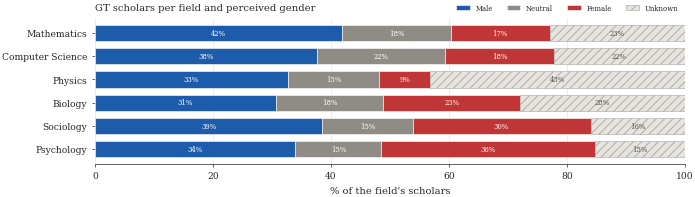

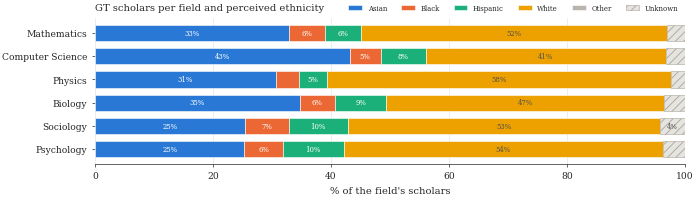

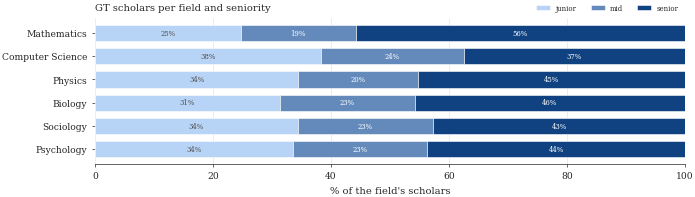

In [5]:
# Scholars per field 
# by seniority, perceived gender, then perceived ethnicity (SHOW_UNKNOWN: 'unknown' as a segment)
POPULATION_NORMALIZE = True
for by in ['gender', 'ethnicity', 'seniority']:
    counts = table(f'population_{by}', lambda by=by: gs.population(con, GT_DIR, by=by))
    display(show(gt_plots.plot_gt_population(counts, by=by, include_unknown=SHOW_UNKNOWN,
                                             normalize=POPULATION_NORMALIZE, gender_labels=GENDER_LABELS),
                 f'gt_population_{by}' + ('_pct' if POPULATION_NORMALIZE else '')))
    # display(counts.pivot(index='field', columns=by, values='n').reindex(gs.field_order(counts['field'].unique())))
plt.close('all')

,n_fields,n,share
0,1,33566461,83.1%
1,2,4527506,11.2%
2,3,1503535,3.7%
3,4,562876,1.4%
4,5,181637,0.4%
5,6,47180,0.1%


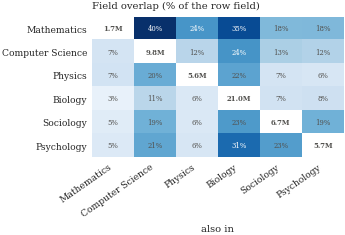

In [6]:
# How many prompt fields a scholar belongs to, and the overlap between fields (% of the row field; diagonal = size)
display(table('fields_per_scholar', lambda: gs.fields_per_scholar(con, GT_DIR)).style.format({'n': '{:.0f}', 'share': '{:.1%}'}))
overlap = table('field_overlap', lambda: gs.field_overlap(con, GT_DIR))
show(gt_plots.plot_gt_field_overlap(overlap), 'gt_field_overlap');

## 2. Seniority (academic age)

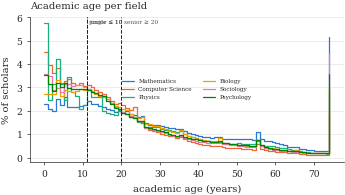

In [7]:
# Academic age = reference year - first publication year, per field, with the seniority cut-offs of the config
s = config['seniority']
age = table('hist_academic_age', lambda: gs.histogram(con, GT_DIR, 'academic_age', 0, 75, 75, by_field=True))
thresholds = {f"junior ≤ {s['junior_max']}": s['junior_max'] + 1, f"senior ≥ {s['senior_min']}": s['senior_min'],
              f"single ≤ {s['single_cutoff']}": s['single_cutoff'] + 1}
show(gt_plots.plot_gt_histogram(age, 'academic age (years)', thresholds, title='Academic age per field'), 'gt_academic_age');

## 3. Bibliometrics

,field,seniority,metric,n,mean,q05,q25,q50,q75,q95
18,All fields,junior,academic_age,16919177,4.84,0.0,2.00,5.00,8.00,10.00
19,All fields,mid,academic_age,11500968,14.73,11.0,12.00,15.00,17.00,19.00
20,All fields,senior,academic_age,22154702,40.77,21.0,25.00,35.00,50.00,82.00
39,All fields,junior,n_works,16919177,5.48,1.0,1.00,2.00,4.00,20.00
40,All fields,mid,n_works,11500968,16.18,1.0,1.00,4.00,16.00,67.00
41,All fields,senior,n_works,22154702,50.14,1.0,2.00,12.00,51.00,214.00
60,All fields,junior,n_citations,16919177,56.28,0.0,0.00,1.00,16.00,211.00
61,All fields,mid,n_citations,11500968,302.36,0.0,0.00,11.00,133.00,1230.00
62,All fields,senior,n_citations,22154702,1274.53,0.0,2.00,60.00,621.00,5630.00
81,All fields,junior,n_coauthors,16919177,14.06,0.0,1.00,5.00,13.00,61.00


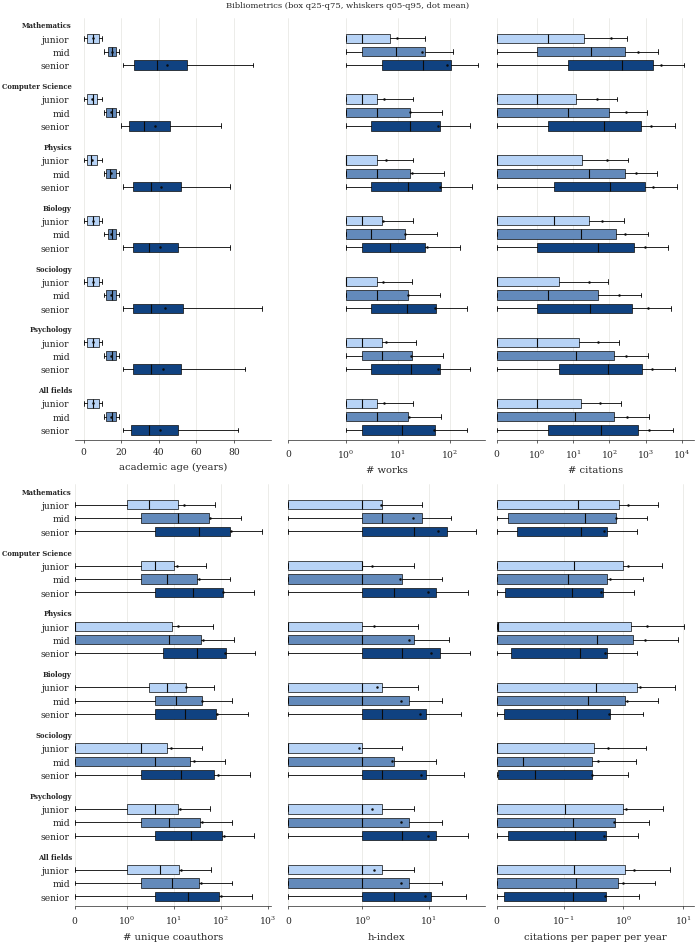

In [8]:
# Per field x seniority: box q25-q75, whiskers q05-q95, line median, dot mean (approximate quantiles)
quantiles = table('bibliometrics', lambda: gs.bibliometric_quantiles(con, GT_DIR, METRICS))
show(gt_plots.plot_gt_bibliometrics(quantiles, METRICS), 'gt_bibliometrics')
quantiles[quantiles['field'] == gs.ALL_FIELDS].round(2)

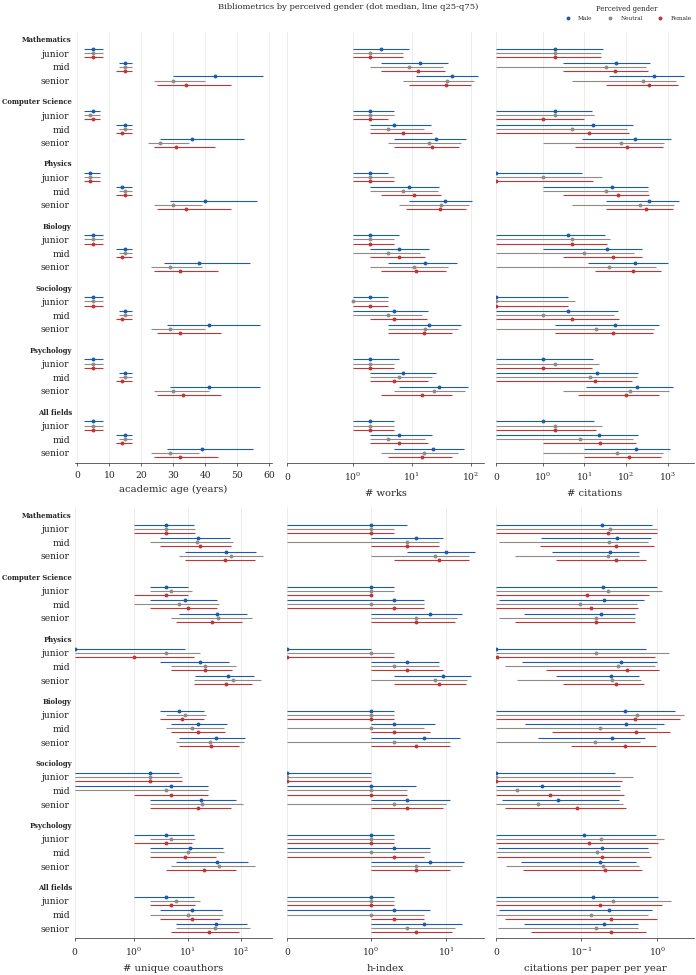

In [9]:
# The same by perceived gender (median, q25-q75): gaps in the GT itself (e.g. citations), within field x seniority
by_gender = table('bibliometrics_by_gender', lambda: gs.bibliometric_quantiles(con, GT_DIR, METRICS, by='gender'))
show(gt_plots.plot_gt_bibliometrics_by(by_gender, 'gender', METRICS, gender_labels=GENDER_LABELS), 'gt_bibliometrics_by_gender');

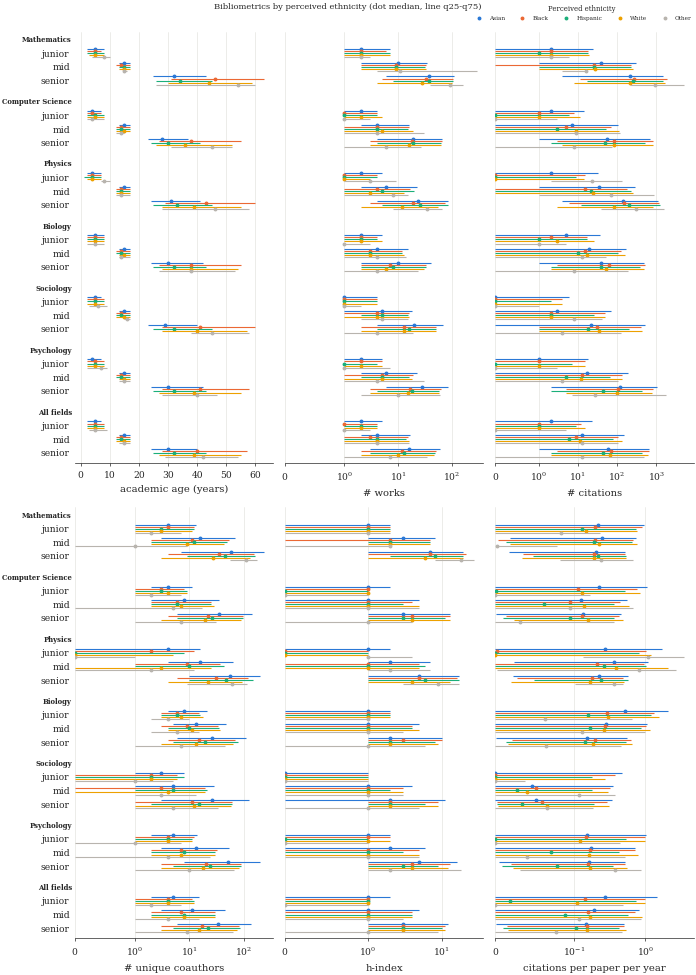

In [10]:
# ... and by perceived ethnicity
by_ethnicity = table('bibliometrics_by_ethnicity', lambda: gs.bibliometric_quantiles(con, GT_DIR, METRICS, by='ethnicity'))
show(gt_plots.plot_gt_bibliometrics_by(by_ethnicity, 'ethnicity', METRICS), 'gt_bibliometrics_by_ethnicity');

## 4. Perceived gender and ethnicity

In [11]:
# Gender labels and why a name is unknown (no usable first name, e.g. initials; or a first name nomquamgender lacks)
table('gender_coverage', lambda: gs.gender_coverage(con, GT_DIR)).style.format({'n': '{:,.0f}', 'share': '{:.1%}'})

,label,n,share
0,male,"12,773,841",31.6%
1,female,"9,208,606",22.8%
2,unknown: no usable first name,"7,097,422",17.6%
3,neutral,"7,009,572",17.4%
4,unknown: first name not in nomquamgender,"4,299,754",10.6%


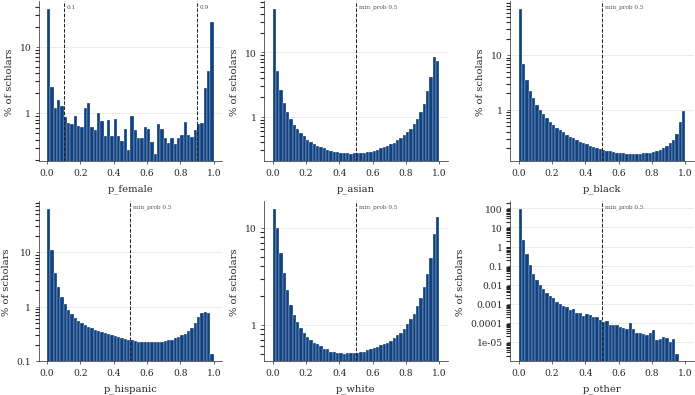

In [12]:
# Inference probabilities with the config thresholds: p_female (gender cut points) and each raceBERT class probability
# (min_prob: a name gets the class with the largest probability if it is >= min_prob, else 'unknown').
# BY_FIELD: one line per field (memberships) instead of bars over all scholars
import matplotlib.pyplot as plt
BY_FIELD = False
ETHNICITY_PROBS = [f'p_{c}' for c in dict.fromkeys(cons.RACEBERT_LABELS.values())]   # p_asian, p_black, ...
edges, min_prob = config['gender']['p_female_edges'], config['ethnicity']['min_prob']
suffix = '_by_field' if BY_FIELD else ''
fig, axes = plt.subplots(2, 3, figsize=(viscons.PAPER_TEXT_WIDTH_IN, 2 * viscons.GT_PANEL_HEIGHT_IN), layout='constrained')
for i, (ax, column) in enumerate(zip(axes.flat, ['p_female', *ETHNICITY_PROBS])):
    hist = table(f'hist_{column}{suffix}', lambda c=column: gs.histogram(con, GT_DIR, c, 0, 1, 50, by_field=BY_FIELD))
    lines = {f"{e}": e for e in edges} if column == 'p_female' else {f"min_prob {min_prob}": min_prob}
    gt_plots.plot_gt_histogram(hist, column, lines, ax=ax, log_y=True, legend=i == 0)
show(fig, f'gt_inference_probabilities{suffix}');

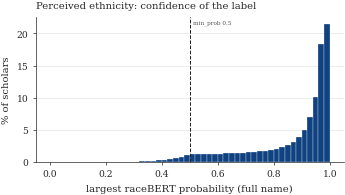

In [13]:
# The largest raceBERT probability of each name: the value min_prob is applied to (left of the line = 'unknown')
p_top = table('hist_p_ethnicity_max', lambda: gs.histogram(con, GT_DIR, 'p_ethnicity_max', 0, 1, 50))
show(gt_plots.plot_gt_histogram(p_top, 'largest raceBERT probability (full name)', {f"min_prob {min_prob}": min_prob},
                                title='Perceived ethnicity: confidence of the label'), 'gt_ethnicity_confidence');

gender                      female   male  neutral  unknown
field            seniority                                 
Mathematics      junior      0.235  0.356    0.176    0.233
                 mid         0.206  0.375    0.219    0.199
                 senior      0.125  0.463    0.174    0.237
Computer Science junior      0.227  0.352    0.198    0.224
                 mid         0.184  0.344    0.258    0.214
                 senior      0.140  0.423    0.211    0.226
Physics          junior      0.099  0.311    0.128    0.462
                 mid         0.088  0.264    0.177    0.471
                 senior      0.077  0.368    0.165    0.390
Biology          junior      0.295  0.283    0.179    0.243
                 mid         0.253  0.272    0.220    0.254
                 senior      0.179  0.339    0.167    0.315
Sociology        junior      0.357  0.329    0.143    0.170
                 mid         0.334  0.337    0.171    0.158
                 senior      0.240  0.457    0.151    0.153
Psychology       junior      0.427  0.278    0.141    0.153
                 mid         0.397  0.289    0.161    0.153
                 senior      0.294  0.414    0.141    0.151
All fields       junior      0.280  0.309    0.168    0.244
                 mid         0.248  0.300    0.210    0.242
                 senior      0.179  0.385    0.169    0.266

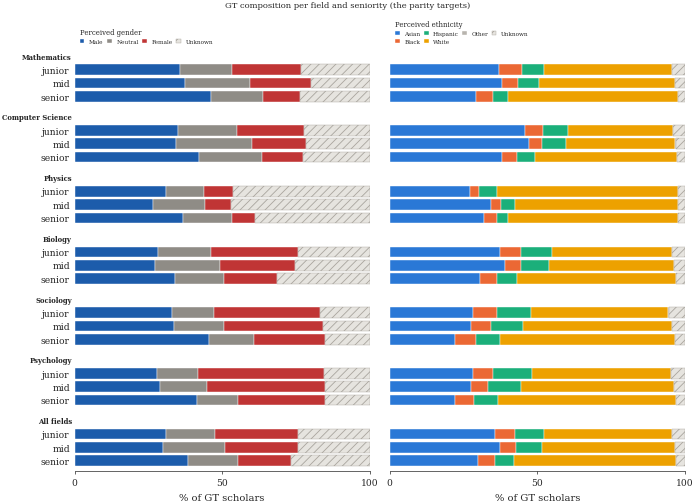

In [14]:
# Composition per field x seniority (+ All fields): the parity targets
show(gt_plots.plot_gt_composition(shares, ['gender', 'ethnicity'], SHOW_UNKNOWN, ncols=2, gender_labels=GENDER_LABELS),
     'gt_composition_demographics')
gs.composition(shares, 'gender', SHOW_UNKNOWN).round(3)

In [15]:
gs.composition(shares, 'ethnicity', SHOW_UNKNOWN).round(3)

ethnicity                   asian  black  hispanic  other  unknown  white
field            seniority                                               
Mathematics      junior     0.369  0.079     0.076    0.0    0.043  0.433
                 mid        0.379  0.057     0.070    0.0    0.032  0.462
                 senior     0.292  0.056     0.051    0.0    0.025  0.575
Computer Science junior     0.458  0.060     0.086    0.0    0.041  0.355
                 mid        0.471  0.046     0.080    0.0    0.032  0.371
                 senior     0.380  0.050     0.062    0.0    0.025  0.483
Physics          junior     0.271  0.031     0.062    0.0    0.024  0.612
                 mid        0.344  0.032     0.049    0.0    0.023  0.553
                 senior     0.318  0.047     0.037    0.0    0.022  0.576
Biology          junior     0.374  0.070     0.107    0.0    0.042  0.407
                 mid        0.391  0.054     0.094    0.0    0.036  0.424
                 senior     0.306  0.056     0.070    0.0    0.031  0.537
Sociology        junior     0.283  0.081     0.116    0.0    0.055  0.464
                 mid        0.275  0.068     0.108    0.0    0.043  0.505
                 senior     0.220  0.072     0.083    0.0    0.032  0.593
Psychology       junior     0.283  0.068     0.130    0.0    0.045  0.474
                 mid        0.274  0.059     0.110    0.0    0.038  0.519
                 senior     0.220  0.065     0.080    0.0    0.031  0.604
All fields       junior     0.358  0.065     0.100    0.0    0.042  0.435
                 mid        0.374  0.053     0.090    0.0    0.035  0.449
                 senior     0.298  0.057     0.067    0.0    0.029  0.549

## 5. Countries (latest affiliation)

country                         ZA      DE      CA      EC      JP
field            seniority                                        
Mathematics      junior     0.0029  0.0213  0.0110  0.0012  0.0104
                 mid        0.0034  0.0264  0.0146  0.0006  0.0134
                 senior     0.0031  0.0389  0.0225  0.0004  0.0360
Computer Science junior     0.0018  0.0182  0.0089  0.0045  0.0116
                 mid        0.0020  0.0221  0.0112  0.0013  0.0179
                 senior     0.0022  0.0324  0.0190  0.0008  0.0468
Physics          junior     0.0014  0.0312  0.0071  0.0003  0.0160
                 mid        0.0015  0.0444  0.0111  0.0002  0.0277
                 senior     0.0018  0.0493  0.0171  0.0003  0.0647
Biology          junior     0.0025  0.0214  0.0112  0.0031  0.0153
                 mid        0.0024  0.0259  0.0130  0.0010  0.0196
                 senior     0.0026  0.0364  0.0184  0.0007  0.0489
Sociology        junior     0.0030  0.0171  0.0094  0.0022  0.0039
                 mid        0.0038  0.0220  0.0138  0.0010  0.0064
                 senior     0.0040  0.0320  0.0237  0.0008  0.0175
Psychology       junior     0.0031  0.0201  0.0159  0.0053  0.0097
                 mid        0.0039  0.0230  0.0185  0.0014  0.0127
                 senior     0.0038  0.0304  0.0274  0.0010  0.0310
All fields       junior     0.0024  0.0211  0.0105  0.0032  0.0123
                 mid        0.0026  0.0261  0.0132  0.0010  0.0173
                 senior     0.0028  0.0361  0.0202  0.0007  0.0437

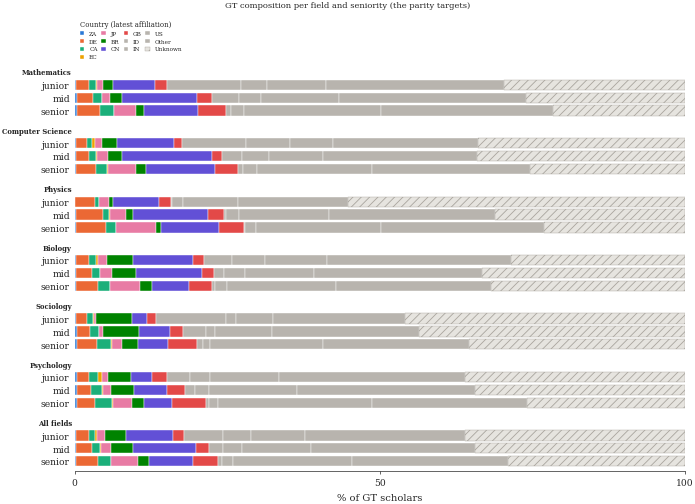

In [16]:
# Top countries + the prompt countries (always shown), the rest pooled as 'other'
show(gt_plots.plot_gt_composition(shares, ['country'], SHOW_UNKNOWN, ncols=1), 'gt_composition_country')
# Share of the prompt countries (baseline of the location drift in 5_flows)
gs.composition(shares, 'country', SHOW_UNKNOWN)[[c for c in prompt_countries() if c in set(shares['class'])]].round(4)

## 6. Prominence classes (productivity, influence, collaboration)

In [17]:
# Value ranges of the rank-based L / M / H bins (ties share a bin, so the bins are not equal-sized: share_<class>)
gs.cutoffs_table(cutoffs, BIN_LABELS).round(3)

,field,seniority,attribute,ranges,share_H,share_L,share_M
0,Mathematics,junior,collaboration,"L 0-2 | M 3-7 | H 8-2,562",0.325,0.424,0.251
1,Mathematics,junior,influence,"L 0-0 | M 1-9 | H 10-168,897",0.326,0.394,0.280
2,Mathematics,junior,productivity,"L 1-1 | M 2-4 | H 5-434,618",0.332,0.394,0.274
3,Mathematics,mid,collaboration,"L 0-4 | M 5-33 | H 34-31,113",0.331,0.358,0.311
4,Mathematics,mid,influence,"L 0-4 | M 5-137 | H 138-298,406",0.333,0.338,0.329
5,Mathematics,mid,productivity,"L 1-3 | M 4-23 | H 24-28,398",0.325,0.334,0.342
6,Mathematics,senior,collaboration,"L 0-10 | M 11-98 | H 99-27,115",0.333,0.343,0.324
7,Mathematics,senior,influence,"L 0-30 | M 31-870 | H 871-898,456",0.333,0.335,0.332
8,Mathematics,senior,productivity,"L 1-10 | M 11-71 | H 72-96,186",0.333,0.340,0.327
9,Computer Science,junior,collaboration,"L 0-2 | M 3-7 | H 8-2,562",0.309,0.364,0.327


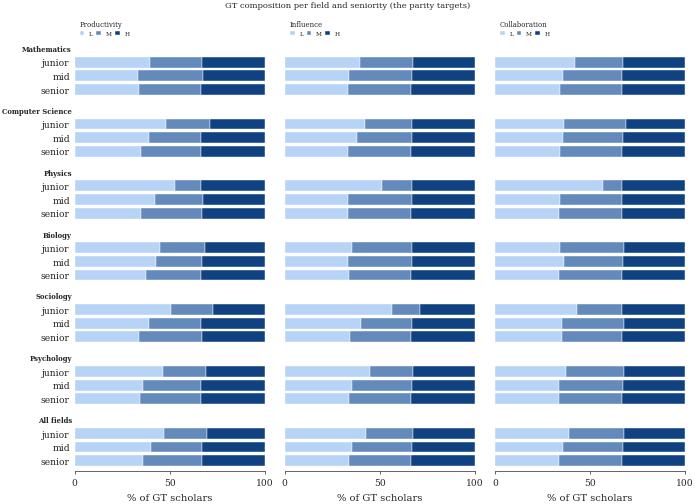

In [18]:
show(gt_plots.plot_gt_composition(shares, ['productivity', 'influence', 'collaboration'], SHOW_UNKNOWN, ncols=3,
                                  bin_labels=BIN_LABELS), 'gt_composition_prominence');

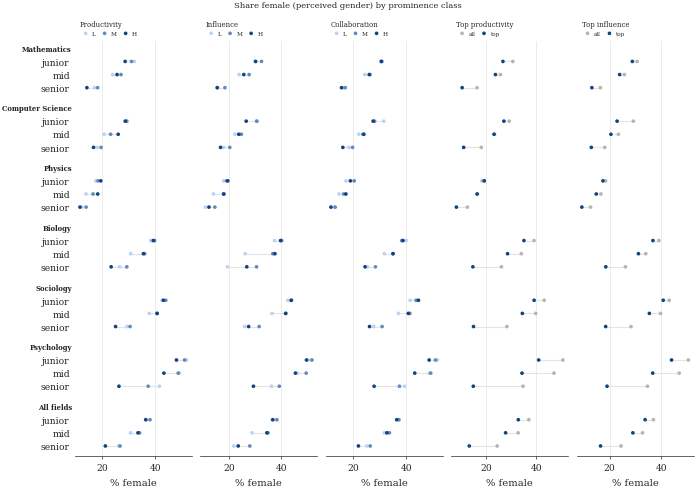

In [19]:
# Perceived gender inside each prominence class and the top x % (vs all members; known labels only, as parity):
# equal dots = the class is spread evenly; a lower 'top' dot = under-represented among the most prominent
gender_prominence = table('gender_by_prominence', lambda: gs.shares_by_prominence(con, GT_DIR, 'gender'))
show(gt_plots.plot_gt_shares_by_prominence(gender_prominence, 'gender', FEMALE, bin_labels=BIN_LABELS),
     f'gt_{FEMALE}_by_prominence');

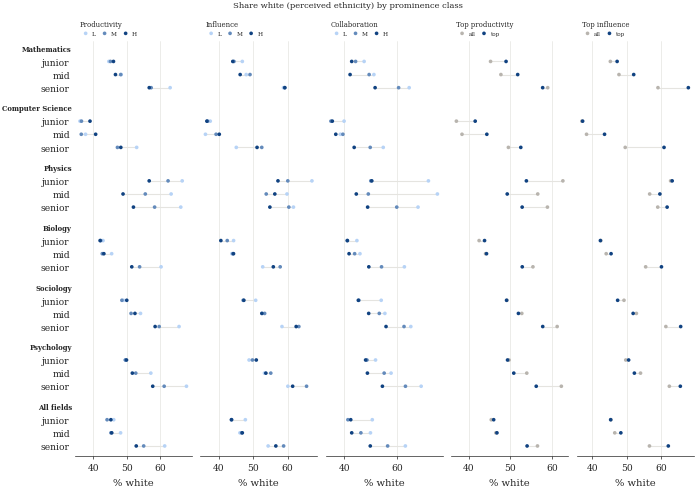

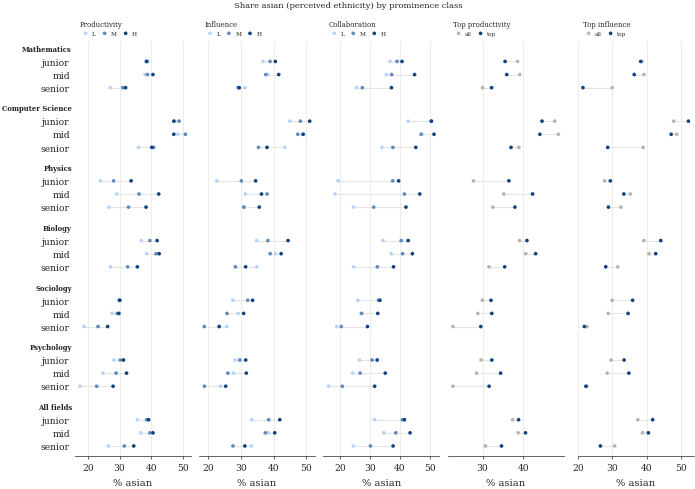

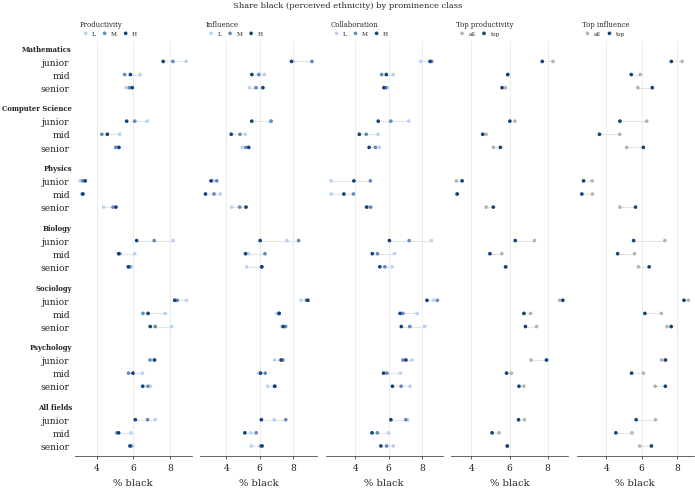

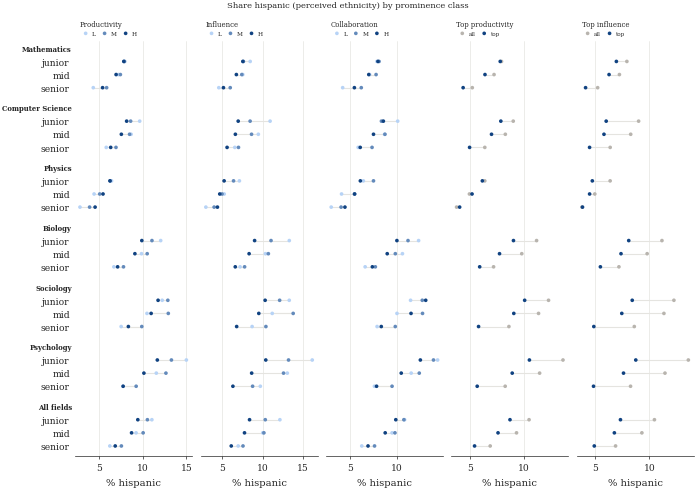

In [20]:
# ... and each perceived ethnicity class
ethnicity_prominence = table('ethnicity_by_prominence', lambda: gs.shares_by_prominence(con, GT_DIR, 'ethnicity'))
for cls in ETHNICITY_CLASSES:
    show(gt_plots.plot_gt_shares_by_prominence(ethnicity_prominence, 'ethnicity', cls, bin_labels=BIN_LABELS),
         f'gt_{cls}_by_prominence')